# calling the bluff that BLEU can't see
## first we load the data and the house scorer

In [1]:
import importlib.util
import re
import collections
import numpy as np
import pandas as pd

spec = importlib.util.spec_from_file_location("bleu", "data/bleu.py")
bleu = importlib.util.module_from_spec(spec)
spec.loader.exec_module(bleu)
tok = bleu.tokenize

refs = pd.read_csv("data/references.csv")
panel = pd.read_csv("data/panel.csv")
ref_map = refs.groupby(["round", "card"]).reference.apply(list).to_dict()

print(refs.shape, panel.shape)
panel.head()

(4800, 3) (2880, 4)


,round,card,seat,text
0,1,1,1,The Punter is a mid range Japanese coffee shop...
1,1,1,2,Near Café Sicilia is a coffee shop with a cust...
2,1,1,3,There is a cheap coffee shop located near Café...
3,1,2,1,Aromi is a Japanese child friendly coffee shop...
4,1,2,2,Aromi is a coffee shop for families that eat h...


## next, we crown the highest BLEU
we are scoring every deck (one panellist's 40 descriptions in one round), with the house score and then pick the top deck per round. just to be clear, this word is NOT the flag.

In [2]:
rows = []
for (rnd, seat), deck in panel.groupby(["round", "seat"]):
    res = bleu.corpus_bleu(list(deck.text), [ref_map[(rnd, c)] for c in deck.card])
    rows.append({"round": rnd, "seat": seat, "bleu": res["bleu"]})
decks = pd.DataFrame(rows)


def decode(seats):
    word = ""
    for i in range(0, len(seats), 3):
        d1, d2, d3 = (s - 1 for s in seats[i:i + 3])
        word += chr(ord("A") + 9 * d1 + 3 * d2 + d3)
    return word


bleu_pick = decks.loc[decks.groupby("round").bleu.idxmax()].sort_values("round").seat.tolist()
print("BLEU's choice: SIGMOID_" + decode(bleu_pick))
decks.pivot(index="round", columns="seat", values="bleu").round(3)

BLEU's choice: SIGMOID_SKELDRAP


seat,1,2,3
round,,,
1,0.467,0.478,0.549
2,0.546,0.422,0.402
3,0.676,0.479,0.337
4,0.428,0.593,0.457
5,0.560,0.541,0.455
6,0.366,0.472,0.381
7,0.582,0.391,0.407
8,0.448,0.578,0.465
9,0.482,0.537,0.403


## what does a description actually say about the venue?
BLEU only compares words, but the same fact can be written in many ways: "cheap" can also mean "affordable", or "less than £20". 
so for every fact (price, rating, family-friendly, area, food, type), we list the phrases people use for each value.
we built these lists by reading every reference and nooting how each value is written. 
we also remove nearby landmark names, so "near Raja Indian Cuisine" does not count as Indian food.
oh and not family friendly is not family friendly, so we remove "yes" if "no" is present. 

In [3]:
FACTS = {
    "price": {
        "cheap":    ["cheap", "less than £20", "under £20", "below £20", "less than 20", "under 20", "low cost", "low priced",
                     "low price", "lower price", "affordable", "inexpensive", "budget"],
        "moderate": ["moderate", "£20 25", "20 25", "£20 to 25", "£20 £25", "20 to 25", "average price", "average priced",
                     "mid price", "mid priced", "mid range", "medium price", "medium priced", "middle price",
                     "reasonably priced", "reasonable price", "prices are average"],
        "high":     ["expensive", "high price", "high priced", "higher price", "highly priced", "more than £30", "over £30",
                     "above £30", "costly", "pricey", "high end", "high cost", "upscale", "higher margin", "prices are high",
                     "price range is high", "priced high"],
    },
    "rating": {
        "1": ["1 out of 5", "one out of five", "1 star", "one star", "low rating", "low customer rating", "low rated",
              "lowly rated", "poor rating", "poorly rated", "poor customer", "rating is low", "ratings are low",
              "low reviews", "low customer review", "poor rated", "1 of 5"],
        "3": ["3 out of 5", "three out of five", "3 star", "three star", "average rating", "average customer rating",
              "average rated", "rated average", "rating is average", "average reviews", "average customer review",
              "3 of 5"],
        "5": ["5 out of 5", "five out of five", "5 star", "five star", "high rating", "high customer rating", "highly rated",
              "high rated", "rating is high", "ratings are high", "top rated", "well rated", "excellent rating",
              "excellent customer", "great reviews", "great rating", "high reviews", "excellent reviews",
              "great customer reviews", "excellent customer feedback", "5 of 5"],
    },
    "family": {
        "no":  ["not family friendly", "not kid friendly", "not kids friendly", "not child friendly", "not children friendly",
                "non family friendly", "isn't family friendly", "isn't kid friendly", "isn't child friendly",
                "not family oriented", "adults only", "adult only", "no families", "no kids", "no children",
                "not for families", "not suitable for famil", "not suitable for kids", "not suitable for children",
                "not allow", "doesn't allow", "not a family", "not favorable for a family"],
        "yes": ["family friendly", "kid friendly", "kids friendly", "child friendly", "children friendly", "family oriented",
                "families are welcome", "families welcome", "welcomes families", "welcomes kids", "welcomes children",
                "for the whole family", "for families", "bring the family", "bring your family", "bring your kids",
                "bring the kids", "friendly for kids", "child frenz", "family pub", "children welcome", "adults and kids"],
    },
    "area": {"riverside": ["river"],
             "city centre": ["city centre", "city center", "centre of the city", "center of the city", "downtown"]},
    "food": {"japanese": ["japan", "sushi"], "italian": ["italian", "pasta", "pizza"], "french": ["french"],
             "indian": ["indian"], "chinese": ["chinese"], "english": ["english", "british"],
             "fast food": ["fast food", "burger", "fries"]},
    "type": {"pub": ["pub"], "coffee shop": ["coffee"], "restaurant": ["restaurant"]},
}

LANDMARKS = ["raja indian cuisine", "rainbow vegetarian cafe", "cafe sicilia", "cafe brazil", "cafe adriatic",
             "cafe rouge", "yippee noodle bar", "crowne plaza hotel", "express by holiday inn", "the portland arms",
             "the rice boat", "all bar one", "clare hall", "the bakers", "ranch", "avalon", "burger king"]


def clean(text):
    t = text.lower().replace("\ufffd", "e").replace("é", "e")
    t = re.sub(r"[^a-z0-9£' ]", " ", t)
    t = " " + re.sub(r"\s+", " ", t) + " "
    for lm in LANDMARKS:
        t = t.replace(" " + lm + " ", " ")
    return t


def claims(text):
    t = clean(text)
    out = {fact: {value for value, phrases in values.items() if any(p in t for p in phrases)}
           for fact, values in FACTS.items()}
    if "no" in out["family"]:            
        out["family"].discard("yes")
    return out


claims("The Wrestlers is a cheap, family-friendly Japanese pub near Raja Indian Cuisine, rated 5 out of 5.")

{'price': {'cheap'},
 'rating': {'5'},
 'family': {'yes'},
 'area': set(),
 'food': {'japanese'},
 'type': {'pub'}}

## is the description complete?
for each card, we take the references agreed upon (so, atleast 2 of the 5 say the same value) plus the names that at least 3 references mention (venue and landmark).
the coverage is the share of those that the description states, and anything below 75% is incomplete.

In [4]:
def names(refs_):
    c = collections.Counter()
    for r in refs_:
        c.update({m.lower() for m in re.findall(r"[A-Z][a-z']+(?:\s+(?:by\s+)?[A-Z][a-z']+)*", r)})
    skip = {"the", "a", "an", "it", "there", "near", "located", "family", "japanese", "italian", "french", "indian",
            "chinese", "english", "fast", "riverside", "city", "in", "for", "with", "this", "its", "they", "customers"}
    return [e for e, n in c.items() if n >= 3 and e not in skip and len(e) >= 4]


def agreed_facts(refs_):
    out = {}
    for fact in FACTS:
        c = collections.Counter(v for r in refs_ for v in claims(r)[fact])
        if c and c.most_common(1)[0][1] >= 2:
            out[fact] = c.most_common(1)[0][0]
    return out


def coverage(text, refs_):
    cl = claims(text)
    have = [value in cl[fact] for fact, value in agreed_facts(refs_).items()]
    low = text.lower()
    have += [n in low for n in names(refs_)]
    return float(np.mean(have)) if have else 1.0


COVER_MIN = 0.75

rl = ref_map[(12, 40)]
print("venue facts:", agreed_facts(rl), "| names:", names(rl))
for seat in (1, 2):
    text = panel[(panel["round"] == 12) & (panel.card == 40) & (panel.seat == seat)].text.iloc[0]
    print(f"seat {seat}: coverage {coverage(text, rl):.2f} | {text}")

venue facts: {'rating': '1', 'family': 'yes', 'area': 'riverside', 'food': 'fast food', 'type': 'restaurant'} | names: ['rouge', 'the golden curry']
seat 1: coverage 0.43 | There is a Fast food restaurant named The Golden Curry.
seat 2: coverage 1.00 | The Golden Curry fast food restaurant is child friendly but has a low customer rating. It can be found on the riverside, near Café Rouge.


## is the descrition padded?
some bluffers glue two descriptions of the same venue together, so every fact is said twice. the extra matching words raise bleu, and the extra length cancels bleus brevity penalty for their short cards
a card is padded if it is longer than 1.2x a normal reference and states at least 2 facts in two different sentences.
(repeating the venue's name doesn't count, people naturally write that.)

In [5]:
PAD_LEN = 1.2


def facts_said_twice(text, refs_):
    sentences = [s for s in re.split(r"(?<=[.!?])\s+", text) if s.strip()]
    if len(sentences) < 2:
        return 0
    facts = agreed_facts(refs_)
    nm = names(refs_)
    venue = max(nm, key=lambda n: sum(n in r.lower() for r in refs_)) if nm else None
    count = sum(1 for fact, value in facts.items() if sum(value in claims(s)[fact] for s in sentences) >= 2)
    count += sum(1 for n in nm if n != venue and sum(n in s.lower() for s in sentences) >= 2)
    return count


def length_ratio(text, refs_):
    return len(tok(text)) / np.median([len(tok(r)) for r in refs_])


def is_padded(text, refs_):
    return length_ratio(text, refs_) > PAD_LEN and facts_said_twice(text, refs_) >= 2


rl = ref_map[(12, 8)]
for seat in (2, 3):
    text = panel[(panel["round"] == 12) & (panel.card == 8) & (panel.seat == seat)].text.iloc[0]
    print(f"seat {seat}: length x{length_ratio(text, rl):.2f}, facts said twice {facts_said_twice(text, rl)}, "
          f"padded {is_padded(text, rl)} | {text}")

seat 2: length x0.58, facts said twice 0, padded False | In the riverside area near Café Brazil, The Vaults is an average priced averagely rated coffee shop.
seat 3: length x1.91, facts said twice 3, padded True | The Vaults is a riverside coffee shop with a price range of £20-£25, but don't let that scare you away. In the riverside area near Café Brazil there is a coffee shop called The Vaults which has a price range of £20-25 and a customer rating of 3 out of 5.


## run both checks from above on every card and counting bluff cards per deck
a card is considered a bluff if it is incomplete or padded. the honest panellist should have 0 bluff cards.
the bluffers have 3 to 28

In [10]:
rows = []
for x in panel.itertuples():
    rl = ref_map[(x.round, x.card)]
    cov = coverage(x.text, rl)
    pad = is_padded(x.text, rl)
    rows.append({"round": x.round, "seat": x.seat, "card": x.card, "coverage": cov,
                 "incomplete": cov < COVER_MIN, "padded": pad, "text": x.text})
cards = pd.DataFrame(rows)
cards["bluff"] = cards.incomplete | cards.padded

table = cards.groupby(["round", "seat"]).bluff.sum().unstack()
honest = table.idxmin(axis=1)
sorted_counts = np.sort(table.values, axis=1)
table["honest seat"] = honest
table["margin"] = sorted_counts[:, 1] - sorted_counts[:, 0]

print("rounds where the honest deck has 0 bluff cards:", int((sorted_counts[:, 0] == 0).sum()), "/ 24")
print("smallest margin to the next deck:", int(table.margin.min()), "cards")
table

rounds where the honest deck has 0 bluff cards: 24 / 24
smallest margin to the next deck: 4 cards


seat,1,2,3,honest seat,margin
round,,,,,
1,0,6,15,1,6
2,7,0,19,2,7
3,20,5,0,3,5
4,7,0,15,2,7
5,5,19,0,3,5
6,23,7,0,3,7
7,0,7,15,1,7
8,4,19,0,3,4
9,27,5,0,3,5


## naming the honest panellist of every round and spelling the flag

In [7]:
honest_seats = table["honest seat"].tolist()
print("honest seats:", honest_seats)
print("BLEU's choice: SIGMOID_" + decode(bleu_pick))
print("Our choice:    SIGMOID_" + decode(honest_seats))
print("BLEU picked the honest panellist in", sum(a == b for a, b in zip(bleu_pick, honest_seats)), "of 24 rounds")

honest seats: [1, 2, 3, 2, 3, 3, 1, 3, 3, 2, 2, 2, 1, 2, 1, 2, 1, 3, 2, 2, 3, 3, 2, 2]
BLEU's choice: SIGMOID_SKELDRAP
Our choice:    SIGMOID_FRINDLOW
BLEU picked the honest panellist in 8 of 24 rounds


## the last step, BLEU vs our check
Top: BLEU per deck. Here we notice that the honest deck (black outline) is often not the highest, so BLEU rewards bluffers.
Bottom: bluff cards per deck. In every round the honest deck sits at the bottom, clearly apart from the two bluffers. 

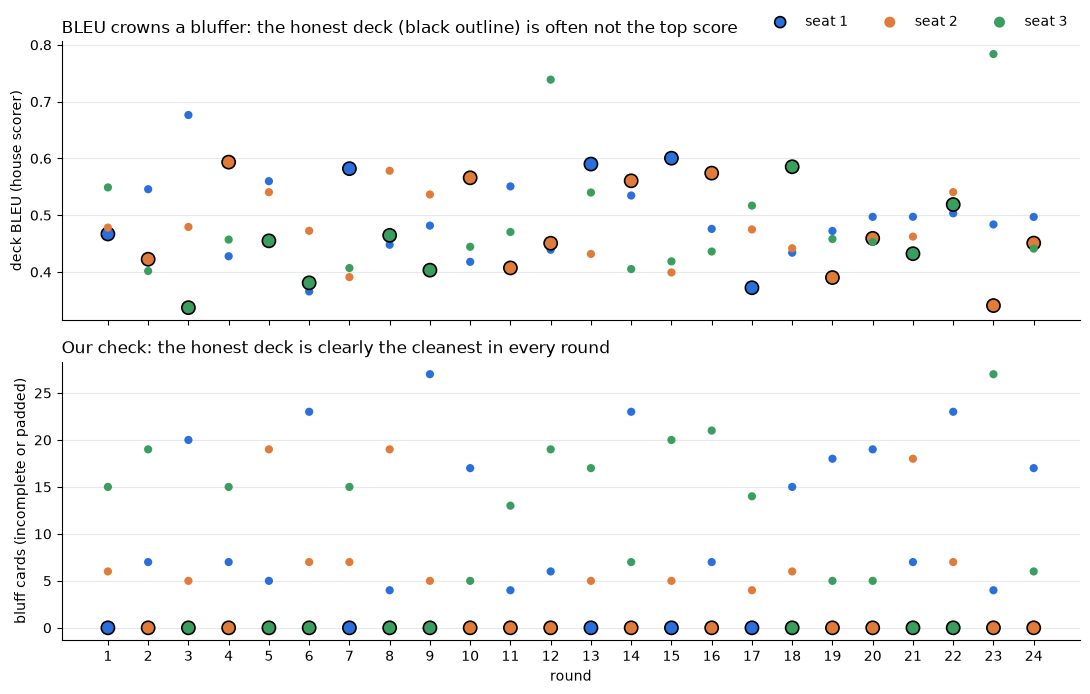

In [8]:
import matplotlib.pyplot as plt

colors = {1: "#2a6fdb", 2: "#e07b39", 3: "#3a9e5f"}
bluff_counts = cards.groupby(["round", "seat"]).bluff.sum().reset_index(name="bluff_cards")
plot = decks.merge(bluff_counts, on=["round", "seat"])
plot["honest"] = [honest_seats[r - 1] == s for r, s in zip(plot["round"], plot.seat)]

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for seat, g in plot.groupby("seat"):
    for ax, col in [(axes[0], "bleu"), (axes[1], "bluff_cards")]:
        ax.scatter(g["round"], g[col], color=colors[seat], label=f"seat {seat}", zorder=3,
                   s=[90 if h else 35 for h in g.honest],
                   edgecolors=["black" if h else "none" for h in g.honest], linewidths=1.2)

axes[0].set_ylabel("deck BLEU (house scorer)")
axes[0].set_title("BLEU crowns a bluffer: the honest deck (black outline) is often not the top score", loc="left")
axes[1].set_ylabel("bluff cards (incomplete or padded)")
axes[1].set_title("Our check: the honest deck is clearly the cleanest in every round", loc="left")
axes[1].set_xlabel("round")
axes[1].set_xticks(range(1, 25))
for ax in axes:
    ax.grid(axis="y", color="#e6e8ec")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, ncol=3, loc="upper right", bbox_to_anchor=(1.0, 1.14))
fig.tight_layout()
fig.savefig("figures/evidence.png", dpi=140)
plt.show()